In [2]:
!git clone https://github.com/rishitha-2602/traffic-accident-risk-analytics.git
%cd /content/traffic-accident-risk-analytics

Cloning into 'traffic-accident-risk-analytics'...
remote: Enumerating objects: 173, done.
remote: Counting objects: 100% (74/74), done.
remote: Compressing objects: 100% (67/67), done.
remote: Total 173 (delta 21), reused 52 (delta 7), pack-reused 99 (from 1)
Receiving objects: 100% (173/173), 125.93 MiB | 26.80 MiB/s, done.
Resolving deltas: 100% (65/65), done.
Updating files: 100% (90/90), done.
/content/traffic-accident-risk-analytics


In [3]:
from pathlib import Path

PROJECT_DIR = Path("/content/traffic-accident-risk-analytics")

for folder in ["data", "notebooks", "models", "reports"]:
    p = PROJECT_DIR / folder
    print(f"\n{folder}: {'FOUND' if p.exists() else 'NOT FOUND'}")
    if p.exists():
        for f in list(p.rglob("*"))[:15]:
            if f.is_file():
                print(" ", f.relative_to(PROJECT_DIR))


data: FOUND
  data/raw/.gitkeep
  data/external/.gitkeep
  data/processed/.gitkeep
  data/processed/crash_cleaned.csv
  data/processed/feature_engineered.csv
  data/raw/2025/charges.csv
  data/raw/2025/.gitkeep

notebooks: FOUND
  notebooks/01_project_setup.ipynb
  notebooks/.gitkeep
  notebooks/05_feature_engineering.ipynb
  notebooks/03_exploratory_data_analysis.ipynb
  notebooks/04_data_cleaning_and_preparation.ipynb
  notebooks/06_baseline_modeling.ipynb
  notebooks/02_data_acquisition_and_inspection.ipynb

models: FOUND
  models/.gitkeep

reports: FOUND
  reports/eda_date_coverage.csv
  reports/.gitkeep
  reports/eda_missing_values.csv
  reports/eda_day_of_week_counts.csv
  reports/cleaning_date_validation.csv
  reports/cleaning_summary.csv
  reports/cleaning_schema_comparison.csv
  reports/cleaning_crash_id_validation.csv
  reports/cleaning_missing_values.csv
  reports/eda_monthly_crash_counts.csv
  reports/eda_severity_distribution.csv
  reports/cleaning_severity_validation.csv


# Step 1: Project Setup and Data Verification

This section verifies the cleaned crash dataset, engineered features, and previous modeling notebook before performing trustworthy AI analysis.


In [4]:
from pathlib import Path
import pandas as pd
import json

PROJECT_DIR = Path("/content/traffic-accident-risk-analytics")

cleaned_path = PROJECT_DIR / "data/processed/crash_cleaned.csv"
features_path = PROJECT_DIR / "data/processed/feature_engineered.csv"

for name, path in [
    ("Cleaned Crash Data", cleaned_path),
    ("Feature-Engineered Data", features_path)
]:
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    if path.exists():
        df = pd.read_csv(path, nrows=5)
        print("File:", path)
        print("Columns:", len(df.columns))
        print("Sample rows:", len(df))
        print("\nColumn names:")
        print(df.columns.tolist())
        print("\nSample data:")
        display(df.head(3))
    else:
        print("File not found:", path)



Cleaned Crash Data
File: /content/traffic-accident-risk-analytics/data/processed/crash_cleaned.csv
Columns: 1
Sample rows: 2

Column names:
['version https://git-lfs.github.com/spec/v1']

Sample data:


,version https://git-lfs.github.com/spec/v1
0,oid sha256:bdda71605c0018ca23cfc705f8cc25a6607...
1,size 246193186



Feature-Engineered Data
File: /content/traffic-accident-risk-analytics/data/processed/feature_engineered.csv
Columns: 14
Sample rows: 5

Column names:
['Crash_ID', 'Source_Year', 'Crash_Year', 'Crash_Month', 'Crash_DayOfWeek', 'Is_Weekend', 'Crash_Hour', 'Time_Period', 'City_ID', 'Latitude', 'Longitude', 'Light_Cond_ID', 'Intrsct_Relat_ID', 'Severity_Target']

Sample data:


,Crash_ID,Source_Year,Crash_Year,Crash_Month,Crash_DayOfWeek,Is_Weekend,Crash_Hour,Time_Period,City_ID,Latitude,Longitude,Light_Cond_ID,Intrsct_Relat_ID,Severity_Target
0,13808771,2021,2021,4,2,0,16,Afternoon,107,32.778415,-96.917012,1,4,Not_Injured
1,17013970,2021,2021,7,4,0,9,Morning,107,32.793116,-96.792534,1,4,NaN
2,17785987,2021,2021,7,6,1,8,Morning,156,32.847844,-97.341874,1,4,Not_Injured



# Step 2: Identify the Target Variable and Modeling Features

Inspect the existing feature-engineering and baseline-modeling workflow to identify the target variable, prediction task, and features used by the model. The same target definition must be used during model evaluation and fairness auditing.


In [5]:
notebook_path = PROJECT_DIR / "notebooks/06_baseline_modeling.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        print(f"\n--- Code Cell {i} ---")
        print(source[:3500])



--- Code Cell 2 ---
%cd /content

!git clone https://github.com/rishitha-2602/traffic-accident-risk-analytics.git traffic-project

--- Code Cell 4 ---
from pathlib import Path

PROJECT_DIR = Path("/content/traffic-project")

for name in [
    "data/processed/crash_cleaned.csv",
    "data/processed/feature_engineered.csv",
]:
    path = PROJECT_DIR / name

    print(f"\nFile: {name}")
    print("Exists:", path.exists())

    if path.exists():
        print("Size (MB):", round(path.stat().st_size / (1024 * 1024), 2))

--- Code Cell 6 ---
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/traffic-project")

raw_path = PROJECT_DIR / "data/processed/crash_cleaned.csv"
feature_path = PROJECT_DIR / "data/processed/feature_engineered.csv"

# Load only the raw columns needed for checking the target mapping
raw = pd.read_csv(
    raw_path,
    usecols=["Crash_ID", "Crash_Sev_ID"],
    low_memory=False
)

features = pd.read_csv(feature_path, low_memory=False)

# Compare t

# Step 3: Verify Severity Labels and Year Coverage

In [6]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/traffic-accident-risk-analytics")
FEATURE_PATH = PROJECT_DIR / "data/processed/feature_engineered.csv"

df = pd.read_csv(FEATURE_PATH, low_memory=False)

print("DATASET SHAPE:", df.shape)
print("\nYEAR-WISE RECORD COUNTS:")
print(df.groupby("Crash_Year").size())

print("\nSEVERITY LABEL COUNTS:")
print(df["Severity_Target"].value_counts(dropna=False))

print("\nSEVERITY DISTRIBUTION BY YEAR:")
display(pd.crosstab(
    df["Crash_Year"],
    df["Severity_Target"],
    dropna=False
))

print("\nMISSING VALUES:")
print(df[[
    "Severity_Target", "City_ID", "Latitude", "Longitude"
]].isnull().sum())

print("\nDUPLICATE CRASH IDs:", df["Crash_ID"].duplicated().sum())

print("\n2025 RECORDS:", (df["Crash_Year"] == 2025).sum())


DATASET SHAPE: (450491, 14)

YEAR-WISE RECORD COUNTS:
Crash_Year
2021    97947
2022    94700
2023    92082
2024    83092
2025    82670
dtype: int64

SEVERITY LABEL COUNTS:
Severity_Target
Not_Injured        273456
Possible_Injury     69741
Minor_Injury        62226
NaN                 30181
Serious_Injury      12322
Fatal_Injury         2565
Name: count, dtype: int64

SEVERITY DISTRIBUTION BY YEAR:


Severity_Target,Fatal_Injury,Minor_Injury,Not_Injured,Possible_Injury,Serious_Injury,NaN
Crash_Year,,,,,,
2021,550,11396,59573,16235,2631,7562
2022,533,12255,57449,14780,2520,7163
2023,530,12761,55932,13769,2424,6666
2024,502,12585,50156,12919,2319,4611
2025,450,13229,50346,12038,2428,4179



MISSING VALUES:
Severity_Target    30181
City_ID                0
Latitude           33766
Longitude          33766
dtype: int64

DUPLICATE CRASH IDs: 0

2025 RECORDS: 82670



# Step 4: Final Model Training and Held-Out Test Evaluation

The Random Forest model had the highest Macro F1-score among the previously reported baseline experiments. This step trains the selected model using labeled records from 2021–2024 and evaluates it on the untouched 2025 test set.

Missing target labels are excluded. Missing predictor values are handled through preprocessing fitted only on the training data.


Training records: 341819
2025 test records: 78491
Training labels: ['Fatal_Injury', 'Minor_Injury', 'Not_Injured', 'Possible_Injury', 'Serious_Injury']
Test labels: ['Fatal_Injury', 'Minor_Injury', 'Not_Injured', 'Possible_Injury', 'Serious_Injury']
Training time (seconds): 676.91

2025 FINAL TEST RESULTS
Accuracy: 0.5581
Balanced accuracy: 0.2376
Macro F1: 0.2379

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

   Fatal_Injury       0.04      0.05      0.04       450
   Minor_Injury       0.26      0.17      0.20     13229
    Not_Injured       0.67      0.79      0.72     50346
Possible_Injury       0.21      0.16      0.18     12038
 Serious_Injury       0.06      0.03      0.04      2428

       accuracy                           0.56     78491
      macro avg       0.25      0.24      0.24     78491
   weighted avg       0.51      0.56      0.53     78491



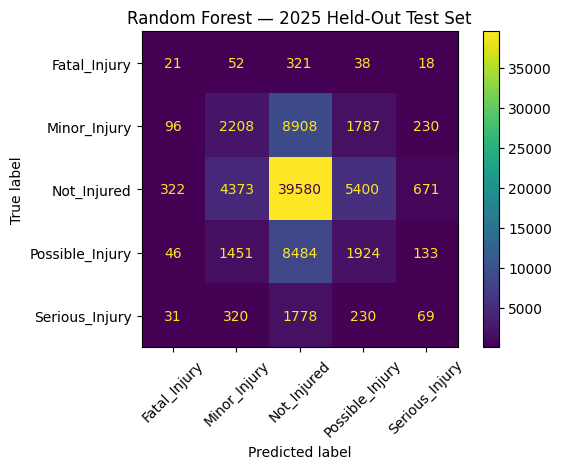


Test labels, predictions, and geographic groups are aligned.


In [7]:
import time
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/traffic-accident-risk-analytics")
FEATURE_PATH = PROJECT_DIR / "data/processed/feature_engineered.csv"

df_model = pd.read_csv(FEATURE_PATH, low_memory=False)

# Remove records without known severity labels
df_model = df_model.dropna(subset=["Severity_Target"]).copy()

numeric_features = [
    "Crash_Month",
    "Crash_DayOfWeek",
    "Is_Weekend",
    "Crash_Hour",
    "Latitude",
    "Longitude"
]

categorical_features = [
    "Time_Period",
    "City_ID",
    "Light_Cond_ID",
    "Intrsct_Relat_ID"
]

feature_cols = numeric_features + categorical_features
target_col = "Severity_Target"

# Chronological split: preserve 2025 as the final test year
train_df = df_model[df_model["Crash_Year"].between(2021, 2024)].copy()
test_df = df_model[df_model["Crash_Year"] == 2025].copy()

X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

print("Training records:", len(X_train))
print("2025 test records:", len(X_test))
print("Training labels:", sorted(y_train.unique()))
print("Test labels:", sorted(y_test.unique()))

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ))
])

start_time = time.time()
final_model.fit(X_train, y_train)
print("Training time (seconds):", round(time.time() - start_time, 2))

# Predictions on the held-out 2025 test set
y_pred_test = final_model.predict(X_test)

print("\n" + "=" * 60)
print("2025 FINAL TEST RESULTS")
print("=" * 60)

print("Accuracy:", round(accuracy_score(y_test, y_pred_test), 4))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test, y_pred_test), 4
))
print("Macro F1:", round(
    f1_score(y_test, y_pred_test, average="macro", zero_division=0), 4
))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_test, zero_division=0))

labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_pred_test, labels=labels)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(xticks_rotation=45, values_format="d")

plt.title("Random Forest — 2025 Held-Out Test Set")
plt.tight_layout()
plt.show()

# Geographic groups aligned to the exact same test rows
test_regions = test_df["City_ID"].reset_index(drop=True)
y_test = y_test.reset_index(drop=True)
y_pred_test = pd.Series(y_pred_test).reset_index(drop=True)

assert len(y_test) == len(y_pred_test) == len(test_regions)

print("\nTest labels, predictions, and geographic groups are aligned.")


# Step 5: Geographic Fairness Audit

Evaluate model performance across City_ID groups in the 2025 held-out test set. Calculate group-level accuracy and positive prediction rate, along with true positive rate, false positive rate, and disparate impact ratio for Fatal_Injury versus all other severity classes.

Only groups with sufficient test records are included. Results measure differences in model behavior across geographic groups; they do not, by themselves, establish the cause of those differences.


In [8]:
from sklearn.metrics import confusion_matrix

audit_df = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred_test,
    "region": test_regions
})

# One-vs-rest definition: Fatal_Injury is the positive class
POSITIVE_CLASS = "Fatal_Injury"
MIN_GROUP_SIZE = 200

audit_df["actual_positive"] = (
    audit_df["actual"] == POSITIVE_CLASS
).astype(int)

audit_df["predicted_positive"] = (
    audit_df["predicted"] == POSITIVE_CLASS
).astype(int)

rows = []

for region, group in audit_df.groupby("region", dropna=False):
    if len(group) < MIN_GROUP_SIZE:
        continue

    y_true_binary = group["actual_positive"]
    y_pred_binary = group["predicted_positive"]

    tn, fp, fn, tp = confusion_matrix(
        y_true_binary,
        y_pred_binary,
        labels=[0, 1]
    ).ravel()

    rows.append({
        "City_ID": region,
        "N": len(group),
        "Accuracy": accuracy_score(
            group["actual"], group["predicted"]
        ),
        "Positive_Prediction_Rate": y_pred_binary.mean(),
        "TPR": tp / (tp + fn) if (tp + fn) else np.nan,
        "FPR": fp / (fp + tn) if (fp + tn) else np.nan
    })

fairness_results = pd.DataFrame(rows)

if fairness_results.empty:
    print("No geographic groups meet the minimum sample size.")
else:
    # Descriptive ratio against the highest group positive-prediction rate
    max_rate = fairness_results["Positive_Prediction_Rate"].max()

    fairness_results["Disparate_Impact_Ratio"] = (
        fairness_results["Positive_Prediction_Rate"] / max_rate
        if max_rate > 0 else np.nan
    )

    fairness_results["Accuracy"] = fairness_results["Accuracy"].round(4)
    fairness_results["Positive_Prediction_Rate"] = (
        fairness_results["Positive_Prediction_Rate"].round(4)
    )
    fairness_results["TPR"] = fairness_results["TPR"].round(4)
    fairness_results["FPR"] = fairness_results["FPR"].round(4)
    fairness_results["Disparate_Impact_Ratio"] = (
        fairness_results["Disparate_Impact_Ratio"].round(4)
    )

    print("FAIRNESS AUDIT — 2025 TEST SET")
    print("Positive class:", POSITIVE_CLASS)
    print("Minimum group size:", MIN_GROUP_SIZE)
    display(fairness_results.sort_values("N", ascending=False))

    output_path = PROJECT_DIR / "reports/geographic_fairness_audit_2025.csv"
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fairness_results.to_csv(output_path, index=False)

    print("\nSaved audit:", output_path)

FAIRNESS AUDIT — 2025 TEST SET
Positive class: Fatal_Injury
Minimum group size: 200


,City_ID,N,Accuracy,Positive_Prediction_Rate,TPR,FPR,Disparate_Impact_Ratio
10,107,23993,0.5594,0.0060,0.0488,0.0057,0.2062
16,156,16153,0.5626,0.0108,0.0727,0.0104,0.3749
1,19,5209,0.3795,0.0060,0.0645,0.0056,0.2059
23,218,4510,0.5470,0.0024,0.0000,0.0024,0.0844
18,177,2985,0.6325,0.0037,0.0000,0.0037,0.1275
17,166,2923,0.4567,0.0021,0.0000,0.0021,0.0710
28,289,2040,0.6966,0.0044,0.0000,0.0044,0.1526
6,67,1673,0.7472,0.0012,0.0000,0.0012,0.0414
30,357,1478,0.3660,0.0027,0.0000,0.0027,0.0936
27,277,982,0.5479,0.0092,0.0000,0.0092,0.3171



Saved audit: /content/traffic-accident-risk-analytics/reports/geographic_fairness_audit_2025.csv


# Step 6 — Model performance chart

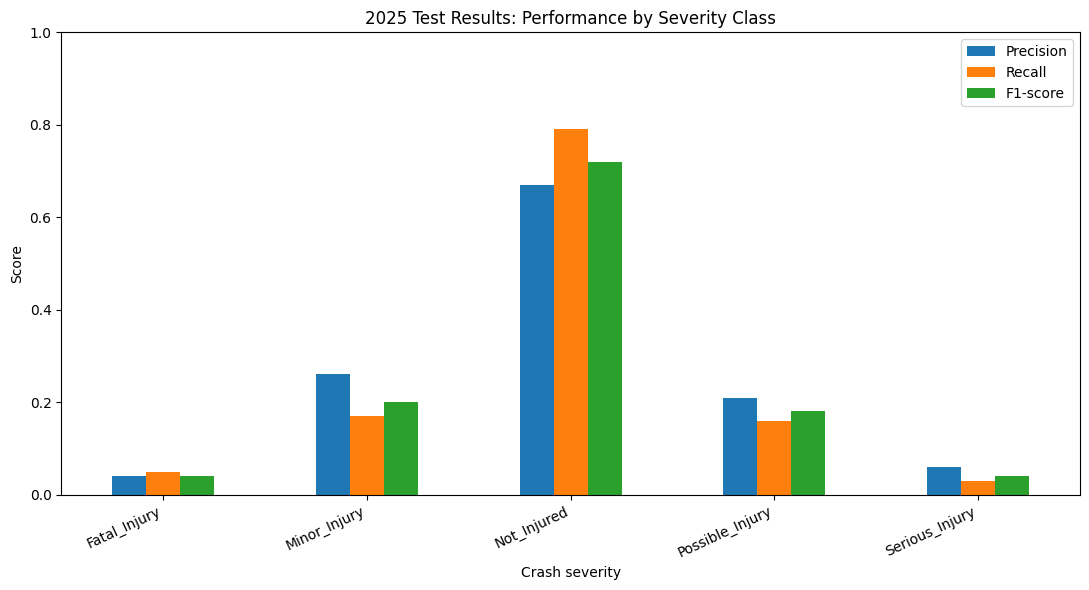

Saved class performance chart and CSV to: /content/traffic-accident-risk-analytics/reports


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/traffic-accident-risk-analytics")
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Class-wise results from your actual 2025 classification report
class_metrics = pd.DataFrame({
    "Severity": [
        "Fatal_Injury",
        "Minor_Injury",
        "Not_Injured",
        "Possible_Injury",
        "Serious_Injury"
    ],
    "Precision": [0.04, 0.26, 0.67, 0.21, 0.06],
    "Recall":    [0.05, 0.17, 0.79, 0.16, 0.03],
    "F1-score":  [0.04, 0.20, 0.72, 0.18, 0.04]
})

ax = class_metrics.set_index("Severity").plot(
    kind="bar", figsize=(11, 6), ylim=(0, 1)
)
ax.set_title("2025 Test Results: Performance by Severity Class")
ax.set_ylabel("Score")
ax.set_xlabel("Crash severity")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="upper right")
plt.tight_layout()

plt.savefig(REPORT_DIR / "class_performance_2025.png", dpi=200)
plt.show()

class_metrics.to_csv(
    REPORT_DIR / "class_performance_2025.csv", index=False
)

print("Saved class performance chart and CSV to:", REPORT_DIR)

# Step 7 — Geographic fairness charts

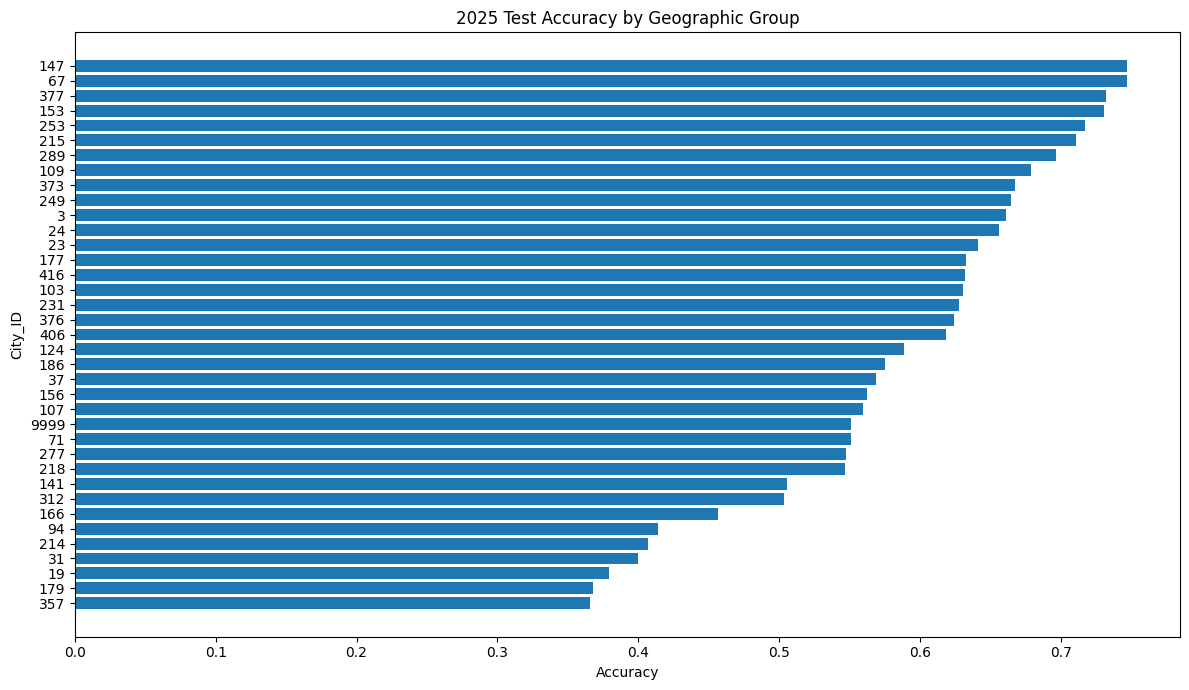

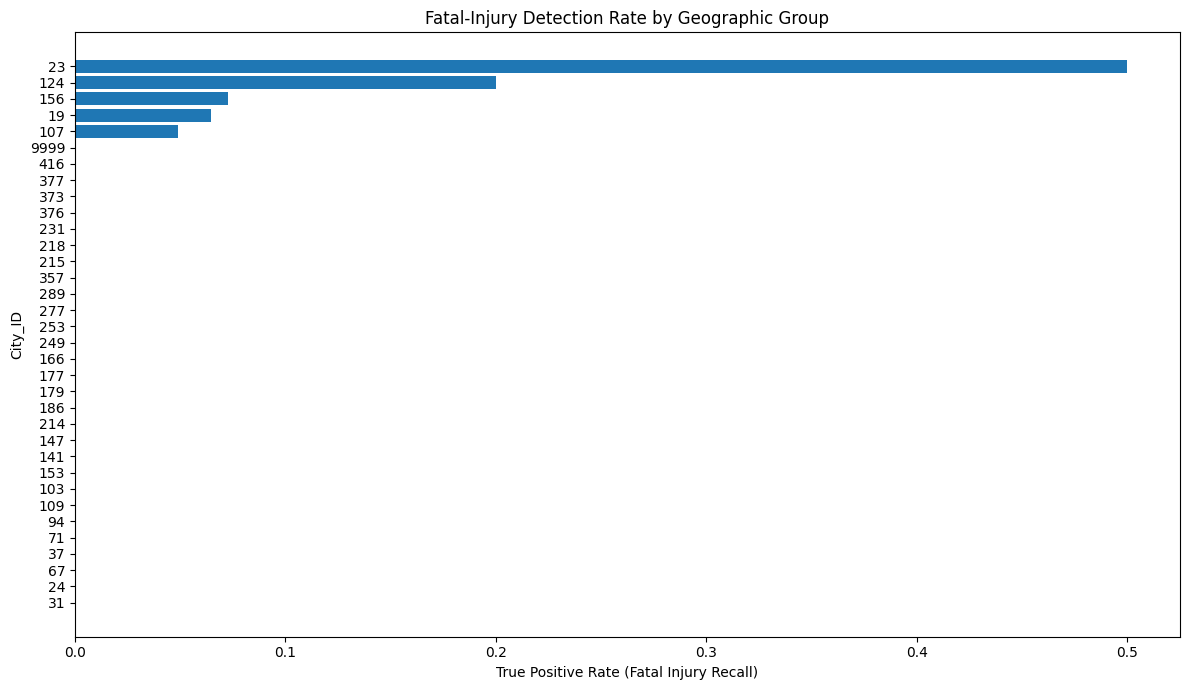

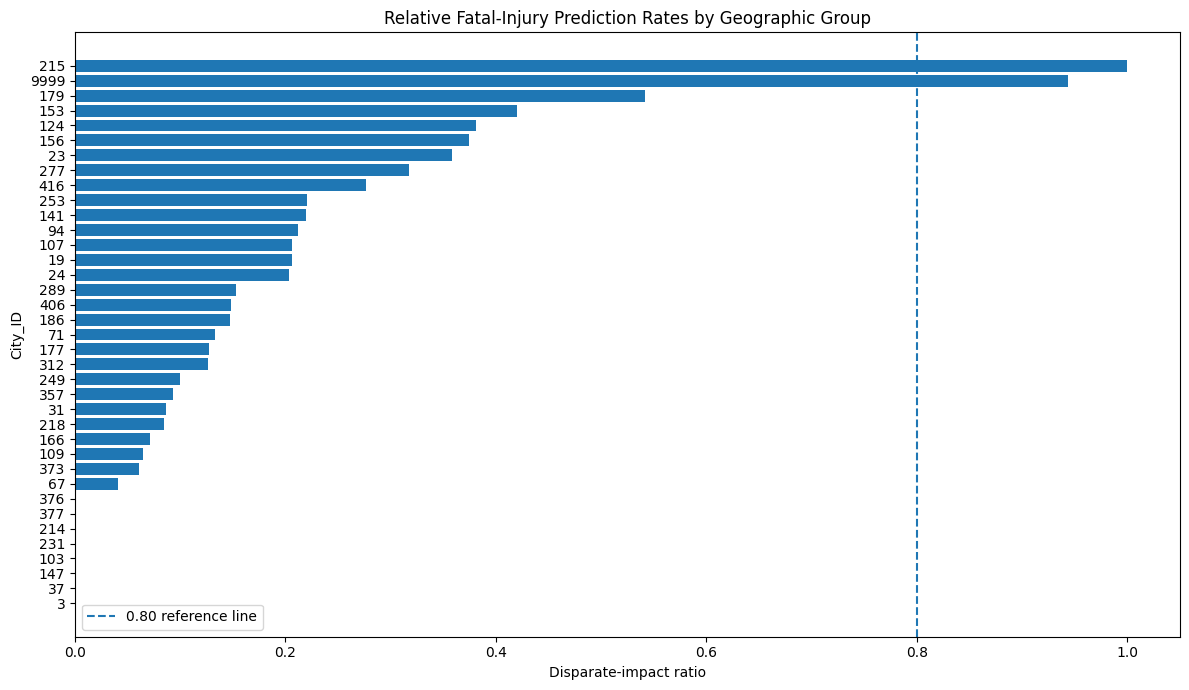

Saved geographic fairness charts to: /content/traffic-accident-risk-analytics/reports


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Exclude groups with missing metrics from the relevant plots
plot_df = fairness_results.copy()
plot_df["City_ID"] = plot_df["City_ID"].astype(str)

# Chart 1: accuracy by city
accuracy_df = plot_df.dropna(subset=["Accuracy"]).sort_values("Accuracy")

plt.figure(figsize=(12, 7))
plt.barh(accuracy_df["City_ID"], accuracy_df["Accuracy"])
plt.xlabel("Accuracy")
plt.ylabel("City_ID")
plt.title("2025 Test Accuracy by Geographic Group")
plt.tight_layout()
plt.savefig(REPORT_DIR / "accuracy_by_city_2025.png", dpi=200)
plt.show()

# Chart 2: fatal-injury recall (TPR) by city
tpr_df = plot_df.dropna(subset=["TPR"]).sort_values("TPR")

plt.figure(figsize=(12, 7))
plt.barh(tpr_df["City_ID"], tpr_df["TPR"])
plt.xlabel("True Positive Rate (Fatal Injury Recall)")
plt.ylabel("City_ID")
plt.title("Fatal-Injury Detection Rate by Geographic Group")
plt.tight_layout()
plt.savefig(REPORT_DIR / "fatal_recall_by_city_2025.png", dpi=200)
plt.show()

# Chart 3: disparate-impact ratio by city
di_df = plot_df.dropna(
    subset=["Disparate_Impact_Ratio"]
).sort_values("Disparate_Impact_Ratio")

plt.figure(figsize=(12, 7))
plt.barh(di_df["City_ID"], di_df["Disparate_Impact_Ratio"])
plt.axvline(0.8, linestyle="--", label="0.80 reference line")
plt.xlabel("Disparate-impact ratio")
plt.ylabel("City_ID")
plt.title("Relative Fatal-Injury Prediction Rates by Geographic Group")
plt.legend()
plt.tight_layout()
plt.savefig(REPORT_DIR / "disparate_impact_by_city_2025.png", dpi=200)
plt.show()

print("Saved geographic fairness charts to:", REPORT_DIR)

# Step 8 — save the findings for your final report

In [11]:
from pathlib import Path

report_text = f"""
TRUSTWORTHY AI AUDIT REPORT
Traffic & Accident Risk Analytics
Evaluation year: 2025

MODEL PERFORMANCE
-----------------
Training records: 341,819
Labeled 2025 test records: 78,491
Accuracy: 0.5581 (55.81%)
Balanced accuracy: 0.2376 (23.76%)
Macro F1-score: 0.2379

KEY FINDINGS
------------
1. Not_Injured had the strongest class performance:
   precision = 0.67, recall = 0.79, F1-score = 0.72.

2. Fatal_Injury performance was weak:
   precision = 0.04, recall = 0.05, F1-score = 0.04.
   The model detected only a small proportion of actual fatal-injury cases.

3. Accuracy alone does not adequately describe this model's
   performance across the five severity classes.

4. Geographic audit results varied across City_ID groups.
   Fatal-injury prediction rates, recall, false-positive rates,
   and accuracy were not uniform.

5. TPR values shown as NaN indicate that a group had no actual
   fatal-injury cases in its test data; recall is undefined for
   that group.

LIMITATIONS
-----------
City_ID is used as a geographic grouping variable. It should not
automatically be interpreted as a verified city name.

The disparate-impact ratio compares each group's fatal-injury
prediction rate with the highest rate among included groups.
It is a descriptive screening measure, not proof of legal fairness.

The model should not be used for real-world safety decisions
without further validation and improvement.

RECOMMENDATIONS
---------------
- Improve fatal-injury detection and minority-class performance.
- Investigate class imbalance and alternative classification methods.
- Review geographic groups with low recall and small positive counts.
- Validate the model and fairness metrics before operational use.
"""

report_path = REPORT_DIR / "trustworthy_ai_audit_report_2025.txt"
report_path.write_text(report_text, encoding="utf-8")

print(report_text)
print("\nSaved report:", report_path)


TRUSTWORTHY AI AUDIT REPORT
Traffic & Accident Risk Analytics
Evaluation year: 2025

MODEL PERFORMANCE
-----------------
Training records: 341,819
Labeled 2025 test records: 78,491
Accuracy: 0.5581 (55.81%)
Balanced accuracy: 0.2376 (23.76%)
Macro F1-score: 0.2379

KEY FINDINGS
------------
1. Not_Injured had the strongest class performance:
   precision = 0.67, recall = 0.79, F1-score = 0.72.

2. Fatal_Injury performance was weak:
   precision = 0.04, recall = 0.05, F1-score = 0.04.
   The model detected only a small proportion of actual fatal-injury cases.

3. Accuracy alone does not adequately describe this model's
   performance across the five severity classes.

4. Geographic audit results varied across City_ID groups.
   Fatal-injury prediction rates, recall, false-positive rates,
   and accuracy were not uniform.

5. TPR values shown as NaN indicate that a group had no actual
   fatal-injury cases in its test data; recall is undefined for
   that group.

LIMITATIONS
-----------

In [12]:
print("Files created in reports/:")
for path in sorted(REPORT_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name} — {path.stat().st_size:,} bytes")

Files created in reports/:
.gitkeep — 0 bytes
accuracy_by_city_2025.png — 95,075 bytes
class_performance_2025.csv — 178 bytes
class_performance_2025.png — 93,331 bytes
cleaning_crash_id_validation.csv — 212 bytes
cleaning_date_validation.csv — 334 bytes
cleaning_decisions.md — 1,198 bytes
cleaning_initial_inventory.csv — 161 bytes
cleaning_missing_values.csv — 26,934 bytes
cleaning_schema_comparison.csv — 541 bytes
cleaning_severity_validation.csv — 1,641 bytes
cleaning_summary.csv — 280 bytes
disparate_impact_by_city_2025.png — 109,261 bytes
eda_data_quality.csv — 283 bytes
eda_date_coverage.csv — 262 bytes
eda_day_of_week_counts.csv — 117 bytes
eda_missing_values.csv — 3,466 bytes
eda_monthly_crash_counts.csv — 364 bytes
eda_severity_distribution.csv — 124 bytes
fatal_recall_by_city_2025.png — 95,080 bytes
geographic_fairness_audit_2025.csv — 1,465 bytes
trustworthy_ai_audit_report_2025.txt — 1,722 bytes
